### **Práctica 5 - Análisis frecuencial de señales**

#### **Presentado por:** Alma Olea Barbosa - Lauren Cordero Ramos 

#### **Semestre:** 2026-2

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import trapezoid
from scipy.io import loadmat

**4.1	Cree una señal que sea la suma de tres componentes sinusoidales con frecuencias de 40, 80 y 160 Hz. Defina la frecuencia de muestreo mínima necesaria para representar la señal, y utilice la frecuencia de muestreo necesaria para representarla apropiadamente.** 

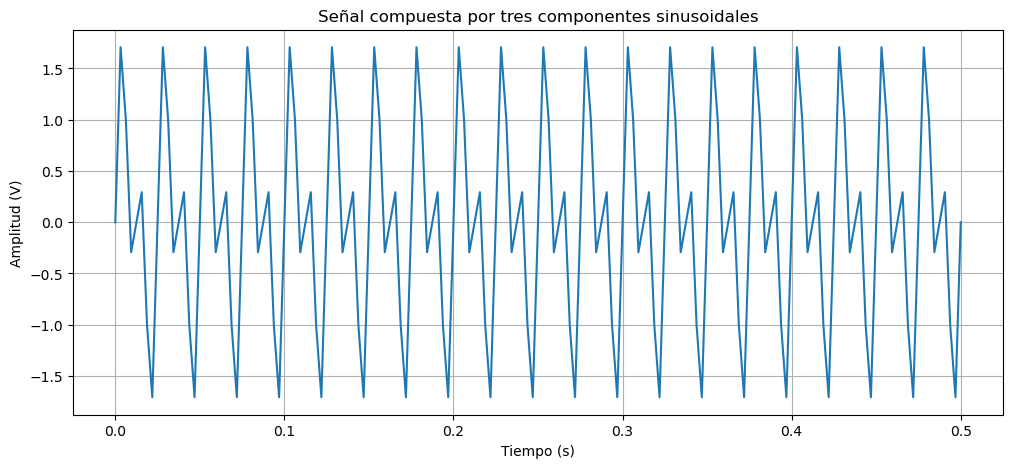

In [ ]:

# Frecuencia de muestreo
fs = 2 * 160 # Teorema de Nyquist

# Periodo de muestreo
T = 1/fs

# Vector de tiempo
t = np.arange(0, 0.5+T, T)

x = (np.sin(2*np.pi*40*t)) + (np.sin(2*np.pi*80*t)) + (np.sin(2*np.pi*160*t))

# Gráfica
plt.figure(figsize=(12,5))
plt.plot(t, x)
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud (V)')
plt.title('Señal compuesta por tres componentes sinusoidales')
plt.grid()
plt.show()

**4.2	Calcule la transformada de Fourier de la señal y grafique el espectro de frecuencia. Identifique en el espectro las frecuencias que componen la señal (trabaje con 10 periodos de la señal).**

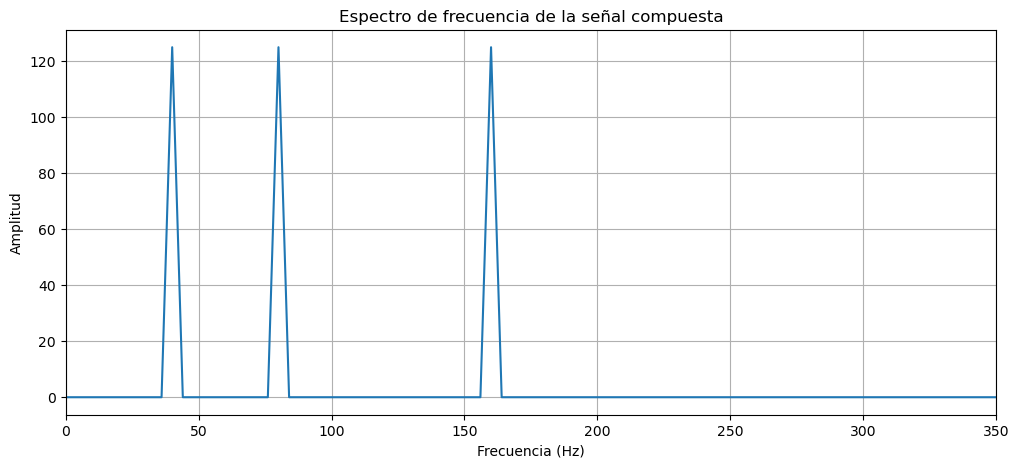

In [ ]:
# Frecuencia de muestreo
Fs = 1000

# Periodo de muestreo
T = 1/Fs

# Tiempo correspondiente a 10 periodos de la frecuencia fundamental f1=40 Hz
t10 = np.arange(0, 10/40, T)

# Señal compuesta por tres componentes sinusoidales
x10 = (np.sin(2*np.pi*40*t10) +
       np.sin(2*np.pi*80*t10) +
       np.sin(2*np.pi*160*t10))

# Transformada Discreta de Fourier
X10 = np.fft.fft(x10)

# Número de muestras
N = len(X10)

# Eje de frecuencias
F = np.arange(0, N)*Fs/N

# Gráfica del espectro de frecuencia
plt.figure(figsize=(12,5))
plt.plot(F[:N//2], np.abs(X10[:N//2]))
plt.title('Espectro de frecuencia de la señal compuesta')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Amplitud')
plt.xlim(0, 350)
plt.grid()
plt.show()


**4.3	Consulte la función que permite realizar el cálculo de la transformada inversa de Fourier. Aplíquelo a la señal anterior.**

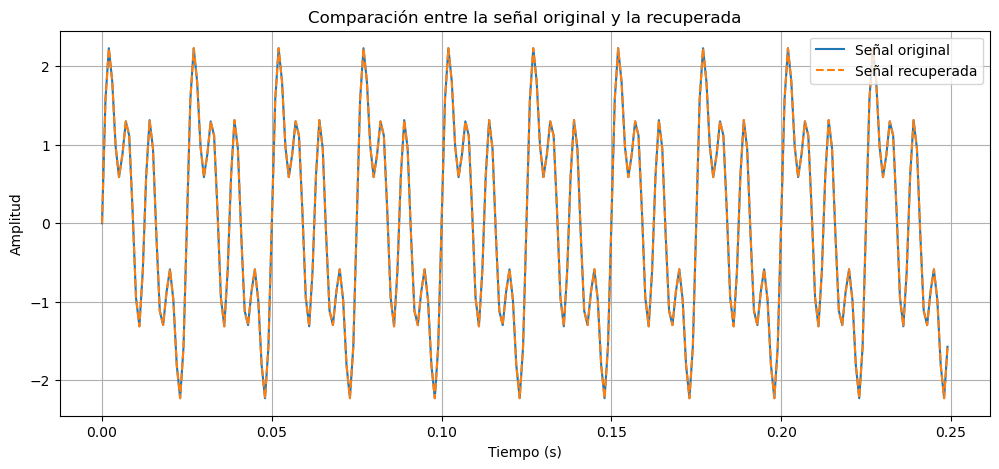

In [ ]:
# Transformada Inversa de Fourier
x_r = np.fft.ifft(X10)

# Gráfica de la señal original y recuperada
plt.figure(figsize=(12,5))

plt.plot(t10, x10, label='Señal original')
plt.plot(t10, x_r.real, '--', label='Señal recuperada')

plt.title('Comparación entre la señal original y la recuperada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()
plt.grid()
plt.show()

**4.4	¿Podría decir que las siguientes líneas aplican un filtro? ¿Por qué?** 

F1 = np.fft.fft(x);
F2 = np.zeros((len(F1)));
F2[9:13] = F1[9:13];
xr = np.fft.ifft(F2);
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(t, np.real(xr))
ax.set(xlabel='Tiempo (s)', ylabel='Amplitud (V)');
plt.show()


Sí, se puede afirmar que estas líneas de código aplican un filtro digital en el dominio de la frecuencia, específicamente es un filtro que permite seleccionar y conservar determinadas componentes frecuenciales de una señal mientras que las demás se eliminan al reemplazarlas por ceros. Primero, se calcula la Transformada de Fourier para pasar la señal del dominio del tiempo al dominio de la frecuencia y luego se crea un vector de ceros en el que únicamente se conservan los valores correspondientes a las posiciones seleccionadas mediante F2[9:13]. Finalmente, se aplica la Transformada Inversa de Fourier para reconstruir la señal utilizando únicamente las frecuencias conservadas. Por esta razón, se considera un filtrado en frecuencia, porque permite conservar determinadas componentes y eliminar las demás. Más específicamente, funciona como un filtro pasabanda en el sentido de que conserva un íntervalo de frecuencias, aunque la selección se realiza directamente sobre los índices de la FFT.


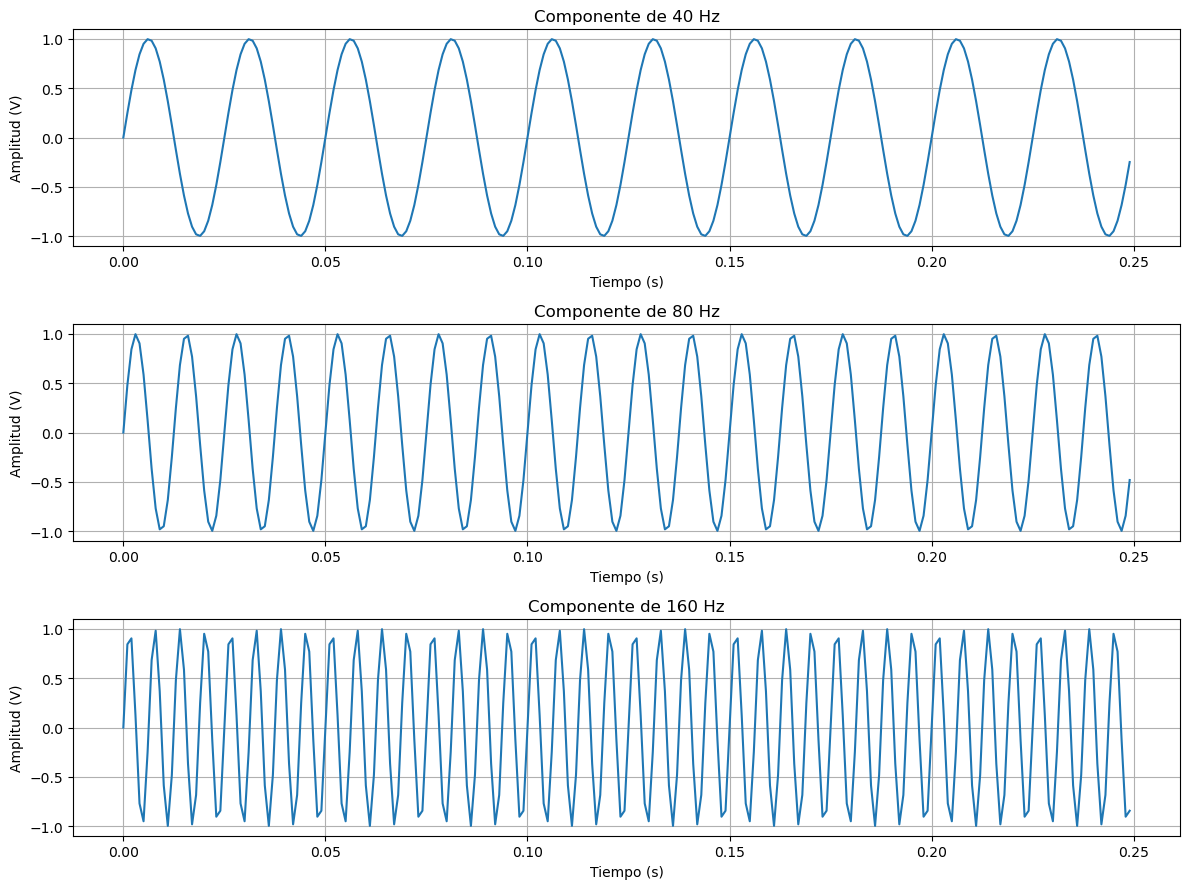

In [ ]:
# Transformada de Fourier de la señal
F1 = np.fft.fft(x10)
N = len(F1)

# Índices de las frecuencias que queremos extraer
indices = [10, 20, 40]

# Frecuencias de cada componente
frecuencias = [40, 80, 160]

fig = plt.figure(figsize=(12, 9))
for i in range(3):

    # Crear vector de ceros
    F2 = np.zeros(N, dtype=complex)
    k = indices[i]
    # Conservar la frecuencia positiva y su simétrica negativa
    F2[k] = F1[k]
    F2[N-k] = F1[N-k]

    xr = np.fft.ifft(F2)

    # Graficar componente recuperada
    ax = fig.add_subplot(3, 1, i+1)
    ax.plot(t10, np.real(xr))

    ax.set(
        title=f'Componente de {frecuencias[i]} Hz',
        xlabel='Tiempo (s)',
        ylabel='Amplitud (V)'
    )

    ax.grid()
plt.tight_layout()
plt.show()

**4.5	Cree una función que calcule manualmente el periodograma de Welch de una señal discreta (usando la DFT), explique paso a paso el algoritmo. Pruébelo e una de las señales construidas anteriormente.**

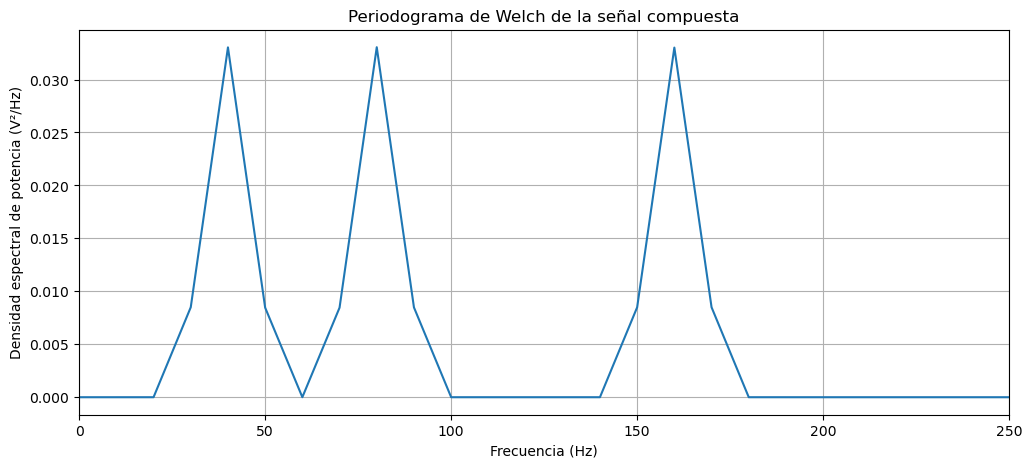

In [ ]:
def welch_manual(x, Fs, nperseg):

    # Paso 1: Dividir la señal en segmentos
    N = len(x)
    paso = nperseg // 2  # Solapamiento del 50%
    segmentos = []
    
    for i in range(0, N - nperseg + 1, paso):
        segmento = x[i:i+nperseg]
        segmentos.append(segmento)

    # Paso 2: Aplicar ventana de Hanning a cada segmento
    ventana = np.hanning(nperseg)

    # Paso 3: Calcular la DFT de cada segmento y su periodograma
    periodogramas = []
    for segmento in segmentos:
        segmento = segmento * ventana
        X = np.fft.rfft(segmento)
        P = (np.abs(X)**2) / (Fs * np.sum(ventana**2))

        # Duplicar las componentes positivas interiores
        if nperseg % 2 == 0:
            P[1:-1] *= 2
        else:
            P[1:] *= 2

        periodogramas.append(P)

    # Paso 4: Promediar los periodogramas
    P_welch = np.mean(periodogramas, axis=0)

    # Paso 5: Calcular el eje de frecuencias
    F = np.fft.rfftfreq(nperseg, d=1/Fs)
    return F, P_welch


# Aplicar el método de Welch a la señal construida anteriormente
F_welch, P_welch = welch_manual(x10, Fs, 100)

# Graficar el resultado
plt.figure(figsize=(12,5))
plt.plot(F_welch, P_welch)
plt.title('Periodograma de Welch de la señal compuesta')
plt.xlabel('Frecuencia (Hz)')
plt.ylabel('Densidad espectral de potencia (V²/Hz)')
plt.xlim(0, 250)
plt.grid()
plt.show()

El método de Welch es una técnica utilizada para estimar la densidad espectral de potencia de una señal discreta. Su funcionamiento consiste en dividir la señal en varios segmentos, aplicar una ventana a cada uno de ellos y calcular su Transformada Discreta de Fourier (DFT). Posteriormente, se obtiene el periodograma de cada segmento y se promedian los resultados para conseguir una estimación más estable del contenido frecuencial de la señal [1].
Para implementar este método, se creó una función en Python que realiza manualmente cada uno de estos pasos, utilizando las funciones de NumPy para el procesamiento de las señales. La función se probó con la señal compuesta por tres componentes sinusoidales de 40 Hz, 80 Hz y 160 Hz. Como resultado, se obtuvo una gráfica de densidad espectral de potencia en la que se identifican las tres frecuencias, comprobando el funcionamiento del método de Welch.

En este ejercicio se utilizó una ventana de Hanning, segmentos de 100 muestras y un solapamiento del 50 %.

**4.6	El archivo adjunto (senecg.mat) contiene una señal de ECG adquirida a una frecuencia de muestreo de 250 Hz. Realice un análisis en frecuencia de la señal usando periodogramas de Welch y determine si es necesario eliminar ruido, en tal caso, elimínelo de la forma que se mostró antes y compruebe que lo haya realizado, calcule la transformada inversa de Fourier de la señal filtrada y compruebe con el periodograma. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja). Compare el método de la librería con la función creada en el punto anterior.**

1250 muestras | 5.0 s | Δf = 0.98 Hz | 8 segmentos


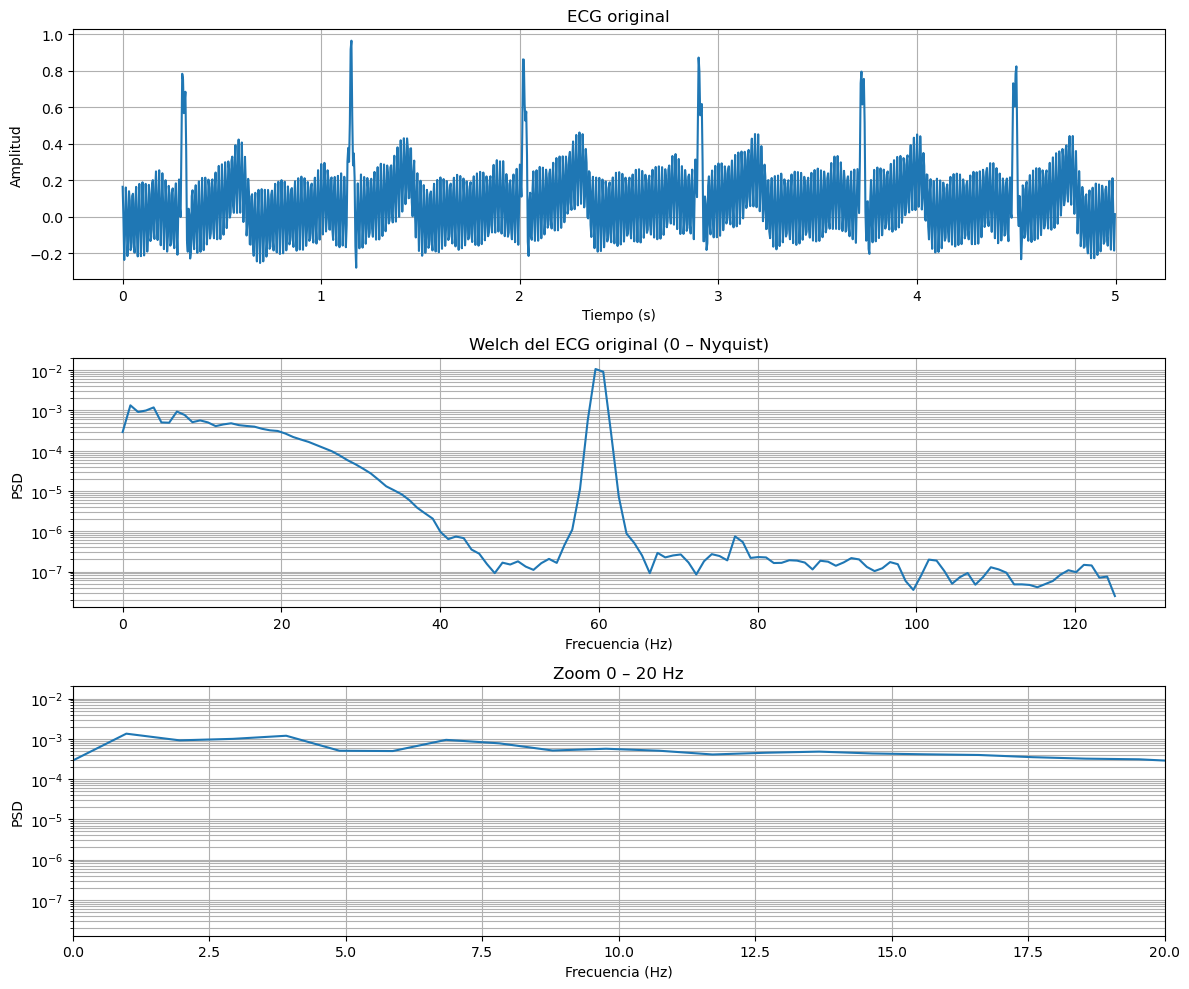


Distribución de potencia:
  < 0.5 Hz (deriva)       :   0.00 %
  0.5-40 Hz (ECG)         :  37.85 %
  40-125 Hz (alta frec.)  :  59.79 %

Búsqueda de interferencia de red (potencia máx. en la banda vs. mediana de su entorno):
  50 Hz: pico en 49.8 Hz | razón 0.1x
  60 Hz: pico en 59.6 Hz | razón 64344.4x

Picos principales del espectro (Hz): [ 0.98  3.91  6.84 59.57]


In [ ]:
Fs = 250
nperseg, noverlap = 512, 256          # 2,05 s y 50 % de solape

# Cargar la señal
mat = loadmat(r"C:\Users\usuario\OneDrive\Desktop\SEMESTRE 2026-2\LAB SEÑALES\Práctica 5\senecg.mat")           

def welch_manual(x, Fs, nperseg, noverlap=None):
    N = len(x)
    if noverlap is None:
        noverlap = nperseg // 2
    paso = nperseg - noverlap
    segmentos = [x[i:i+nperseg] for i in range(0, N - nperseg + 1, paso)]
    ventana = np.hanning(nperseg)
    periodogramas = []
    for seg in segmentos:
        seg = seg - np.mean(seg)                          # Se quita la media del segmento
        X = np.fft.rfft(seg * ventana)
        P = (np.abs(X)**2) / (Fs * np.sum(ventana**2))
        P[1:-1] *= 2 if nperseg % 2 == 0 else 1
        if nperseg % 2 != 0:
            P[1:] *= 2
        periodogramas.append(P)
    return np.fft.rfftfreq(nperseg, d=1/Fs), np.mean(periodogramas, axis=0)

trapz = getattr(np, "trapezoid", None) or np.trapz        

Fs = 250
nperseg, noverlap = 256, 128        # 1,02 s, 50 % -> 8 segmentos en 5 s

mat = loadmat(r"C:\Users\usuario\OneDrive\Desktop\SEMESTRE 2026-2\LAB SEÑALES\Práctica 5\senecg.mat")        
ecg = np.squeeze(mat['ECG']).astype(float)
assert not np.isnan(ecg).any(), "La señal tiene NaN"
t = np.arange(len(ecg)) / Fs
n_seg = (len(ecg) - noverlap) // (nperseg - noverlap)
print(f"{len(ecg)} muestras | {len(ecg)/Fs:.1f} s | Δf = {Fs/nperseg:.2f} Hz | {n_seg} segmentos")

f, P = welch_manual(ecg, Fs, nperseg, noverlap)

fig, axs = plt.subplots(3, 1, figsize=(12, 10))
axs[0].plot(t, ecg); axs[0].set_xlabel('Tiempo (s)'); axs[0].set_ylabel('Amplitud')
axs[0].set_title('ECG original'); axs[0].grid(True)
axs[1].semilogy(f, P); axs[1].set_xlabel('Frecuencia (Hz)'); axs[1].set_ylabel('PSD')
axs[1].set_title('Welch del ECG original (0 – Nyquist)'); axs[1].grid(True, which='both')
axs[2].semilogy(f, P); axs[2].set_xlim(0, 20); axs[2].set_xlabel('Frecuencia (Hz)'); axs[2].set_ylabel('PSD')
axs[2].set_title('Zoom 0 – 20 Hz'); axs[2].grid(True, which='both')
plt.tight_layout(); plt.show()

total = trapz(P, f)
print("\nDistribución de potencia:")
for nombre, (lo, hi) in {"< 0.5 Hz (deriva)": (0, 0.5), "0.5-40 Hz (ECG)": (0.5, 40),
                         "40-125 Hz (alta frec.)": (40, 125)}.items():
    b = (f >= lo) & (f < hi)
    print(f"  {nombre:24s}: {100*trapz(P[b], f[b])/total:6.2f} %")

print("\nBúsqueda de interferencia de red (potencia máx. en la banda vs. mediana de su entorno):")
for fr in (50, 60):
    banda = (f >= fr-2) & (f <= fr+2)
    vecino = ((f >= fr-15) & (f < fr-5)) | ((f > fr+5) & (f <= fr+15))
    razon = P[banda].max() / np.median(P[vecino])
    print(f"  {fr} Hz: pico en {f[banda][np.argmax(P[banda])]:.1f} Hz | razón {razon:.1f}x")

pk, _ = signal.find_peaks(P, prominence=P.max()*0.01)
print("\nPicos principales del espectro (Hz):", np.round(f[pk][:10], 2))

Máx. parte imaginaria: 1.051479542601559e-16


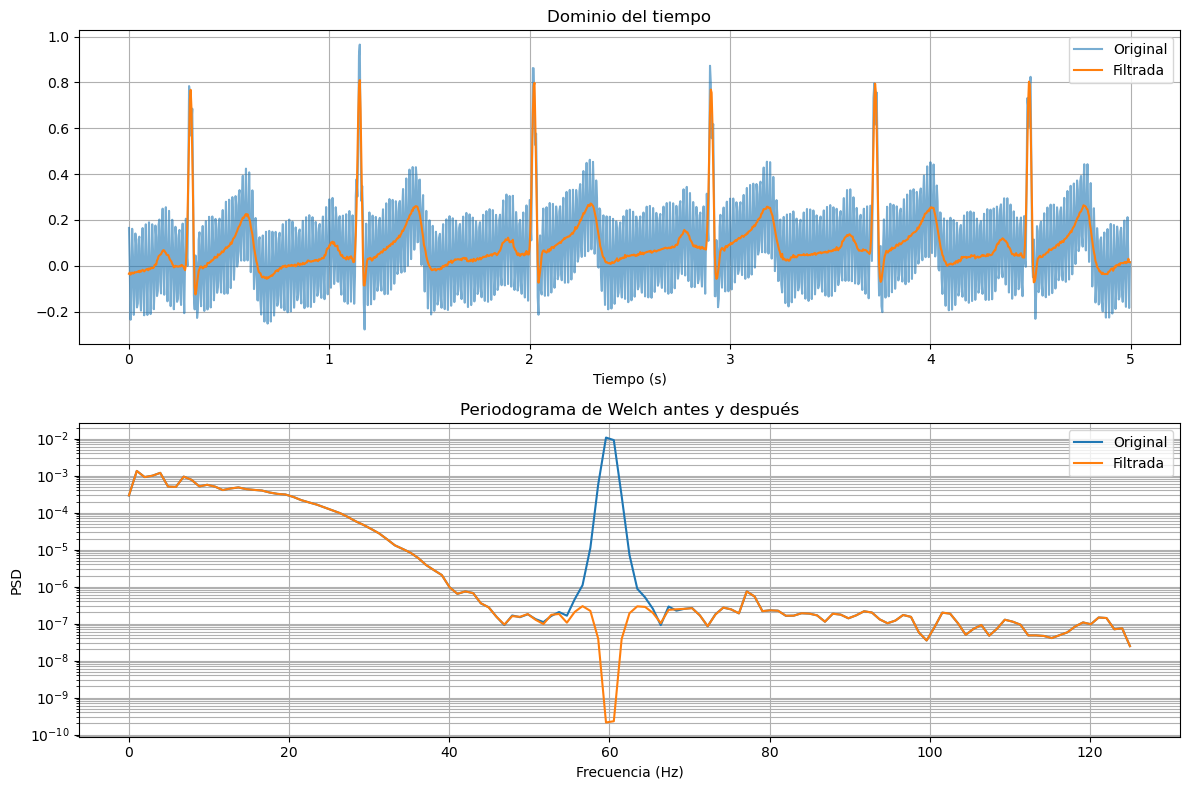

PSD máx. alrededor de 60 Hz: antes 1.07e-02 | después 3.93e-08
Máx. diferencia relativa (manual vs. scipy): 1.6151200520086585e-16


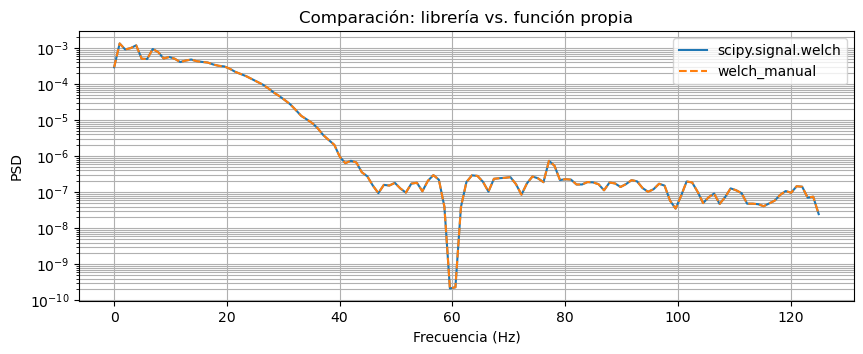

In [ ]:
X  = np.fft.fft(ecg)
fr = np.fft.fftfreq(len(ecg), d=1/Fs)
mascara = np.ones(len(ecg))
mascara[np.abs(np.abs(fr) - 60) <= 2] = 0          # elimina 60 ± 2 Hz (con bins espejo)
ecg_ifft = np.fft.ifft(X * mascara)                # transformada inversa
print("Máx. parte imaginaria:", np.max(np.abs(ecg_ifft.imag)))
ecg_f = ecg_ifft.real


f2, P2 = welch_manual(ecg_f, Fs, nperseg, noverlap)

fig, axs = plt.subplots(2, 1, figsize=(12, 8))
axs[0].plot(t, ecg, alpha=0.6, label='Original'); axs[0].plot(t, ecg_f, label='Filtrada')
axs[0].set_xlabel('Tiempo (s)'); axs[0].set_title('Dominio del tiempo'); axs[0].legend(); axs[0].grid(True)
axs[1].semilogy(f, P, label='Original'); axs[1].semilogy(f2, P2, label='Filtrada')
axs[1].set_xlabel('Frecuencia (Hz)'); axs[1].set_ylabel('PSD')
axs[1].set_title('Periodograma de Welch antes y después'); axs[1].legend(); axs[1].grid(True, which='both')
plt.tight_layout(); plt.show()

b = np.abs(f - 60) <= 2
print(f"PSD máx. alrededor de 60 Hz: antes {P[b].max():.2e} | después {P2[b].max():.2e}")

# -La comparación con la función de scipy.signal.welch
f_sp, P_sp = signal.welch(ecg_f, Fs, window=np.hanning(nperseg),
                          nperseg=nperseg, noverlap=noverlap, detrend='constant')
print("Máx. diferencia relativa (manual vs. scipy):", np.max(np.abs(P2 - P_sp))/np.max(P_sp))

plt.figure(figsize=(10, 3.5))
plt.semilogy(f_sp, P_sp, label='scipy.signal.welch'); plt.semilogy(f2, P2, '--', label='welch_manual')
plt.xlabel('Frecuencia (Hz)'); plt.ylabel('PSD'); plt.legend(); plt.grid(True, which='both')
plt.title('Comparación: librería vs. función propia'); plt.show()

##### Parámetros de Welch
La señal tiene 1250 muestras (5 s) a Fs = 250 Hz. Se usó ventana **Hanning de 256 muestras (1 s)** con **solapamiento del 50 %** (8 segmentos, Δf ≈ 0,98 Hz).

- **Ancho de ventana:** el registro es corto, así que una ventana más larga deja muy pocos segmentos (con 512 muestras solo 3) y una más corta ensancha los picos. Con 256 muestras se aísla bien un pico estrecho como el de la red, aunque no se separan la frecuencia cardiaca y sus armónicos.
- **Solapamiento:** Hanning atenúa los bordes de cada segmento y el 50 % los recupera, duplicando los segmentos promediados (de 4 a 8) sin que queden demasiado correlacionados.

##### ¿Fue necesario eliminar ruido?
Sí. El periodograma muestra un pico muy marcado en **60 Hz** (interferencia de red), con una potencia mayor que la del propio ECG, que en el tiempo se ve como una oscilación rápida que oculta las ondas P y T. No hay pico en 50 Hz, ni deriva de línea base (0,00 % de la potencia bajo 0,5 Hz), ni otro ruido de alta frecuencia, por lo que basta con eliminar la banda de 60 Hz.

##### Filtrado y verificación
Se aplicó un filtro rechazabanda ideal: FFT, anulación de 60 ± 2 Hz (incluidas las frecuencias negativas, para obtener una señal real) y transformada inversa con np.fft.ifft.

- **En el tiempo:** desaparece la oscilación y se distinguen las ondas P, QRS y T.
- **En el periodograma:** la PSD en 60 Hz bajó de 1,07·10⁻² a 3,93·10⁻⁸ (más de cinco órdenes de magnitud) y el resto del espectro no cambió.
- **Limitación:** un filtro ideal de corte abrupto distorsiona levemente los bordes rápidos del QRS.

##### Comparación con la librería
welch_manual y scipy.signal.welch, con los mismos parámetros dan curvas superpuestas con una diferencia relativa máxima de **1,6·10⁻¹⁶** (error de redondeo). Ambas implementan el mismo algoritmo; la librería está optimizada y valida los parámetros, y la función propia muestra cada paso. Se usó la misma ventana en las dos (np.hanning), porque la ventana periódica que scipy usa por defecto da una diferencia de orden 10⁻².

**4.7	Realice un análisis de frecuencia a través del periodograma de welch de una señal de EKG de un paciente Sano y otra de un paciente con alguna condición cardiaca que en el proyecto 1 hayan identificado que presentaba diferencias, si no encontró diferencias, elija un par al azar. Realice un análisis comparativo de las señales según lo que le indiquen los periodogramas. (Usar una ventana Hanning, y justificar la elección del solapamiento y el ancho de la ventaja)**

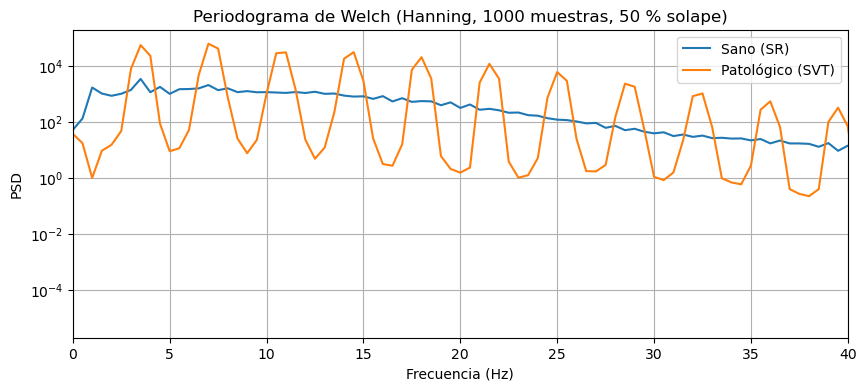

,Señal,Frec. pico (Hz),% 0.5-5 Hz,% 5-15 Hz,% 15-40 Hz
0,Sano (SR),3.5,27.5,52.4,20.1
1,Patológico (SVT),7.0,23.0,58.9,18.1


In [ ]:
ruta_sano = r"C:\Users\usuario\OneDrive\Desktop\SEMESTRE 2026-2\LAB SEÑALES\Práctica 5\SujetoSano.csv"
ruta_SVT  = r"C:\Users\usuario\OneDrive\Desktop\SEMESTRE 2026-2\LAB SEÑALES\Práctica 5\SujetoConSVT.csv"
fs = 500

def cargar(ruta):
    return pd.read_csv(ruta, header=None, usecols=[1]).iloc[:, 0].to_numpy(dtype=float)  # derivación II

x_sano, x_SVT = cargar(ruta_sano), cargar(ruta_SVT)

# Welch: Hanning, 1000 muestras (2 s), 50 % de solape
kw = dict(fs=fs, window='hann', nperseg=1000, noverlap=500)
f, P_sano = signal.welch(x_sano, **kw)
_, P_svt  = signal.welch(x_SVT,  **kw)

# Gráfica
plt.figure(figsize=(10, 4))
plt.semilogy(f, P_sano, label='Sano (SR)')
plt.semilogy(f, P_svt,  label='Patológico (SVT)')
plt.xlim(0, 40)
plt.xlabel('Frecuencia (Hz)'); plt.ylabel('PSD')
plt.title('Periodograma de Welch (Hanning, 1000 muestras, 50 % solape)')
plt.legend(); plt.grid(True, which='both'); plt.show()

# Datos para el análisis comparativo
filas = []
for nombre, P in [("Sano (SR)", P_sano), ("Patológico (SVT)", P_pat)]:
    m = (f >= 0.5) & (f <= 20)
    tot = (f >= 0.5) & (f <= 40)
    fila = {"Señal": nombre, "Frec. pico (Hz)": round(f[m][np.argmax(P[m])], 2)}
    for lo, hi in [(0.5, 5), (5, 15), (15, 40)]:
        b = (f >= lo) & (f <= hi)
        fila[f"% {lo}-{hi} Hz"] = round(100*trapezoid(P[b], f[b])/trapezoid(P[tot], f[tot]), 1)
    filas.append(fila)
display(pd.DataFrame(filas))

#### Justificación de los parámetros de Welch

- **Ventana Hanning de 1000 muestras (2 s).** La resolución en frecuencia es Δf = 500/1000 = 0,5 Hz. Dos segundos abarcan varios latidos en ambos registros y esa resolución permite separar los armónicos del SVT, que están aproximadamente cada 3,6 Hz. Como los registros duran solo 10 s, una ventana más larga dejaría muy pocos segmentos para promediar, y una más corta ensancharía los picos y borraría los armónicos.
- **Solapamiento del 50 % (500 muestras).** Hanning atenúa los extremos de cada segmento, y con 50 % esas muestras quedan en el centro del segmento siguiente. Así se obtienen 9 segmentos en lugar de 5 para promediar, lo que reduce la varianza de la estimación.

#### Análisis comparativo

- **Forma del espectro.** El SVT presenta un espectro en forma de peine, con picos equiespaciados cada 3,6 Hz y valles profundos entre ellos (los picos superan 10⁴ y los valles bajan a ~10⁰). Indica una señal muy periódica. El sano presenta un espectro liso y continuo, cercano a 10³ entre 1 y 15 Hz, que decae suavemente hasta ~10¹ cerca de 40 Hz.
- **Frecuencia cardiaca y armónicos.** El espaciado entre picos del SVT corresponde a su frecuencia fundamental (3,6 Hz, ≈ 210 lpm). En el sano la fundamental es mucho más baja (1,1 Hz), así que sus armónicos están separados menos que el ancho del lóbulo principal de la ventana y se fusionan en un espectro continuo.
- **Frecuencia pico.** No coincide con la frecuencia cardiaca. En el SVT cae en 7,0 Hz, el segundo armónico, porque el QRS reparte su energía entre varios armónicos y alguno supera a la fundamental. En el sano, 3,5 Hz es solo una ligera elevación sobre un espectro casi plano.
- **Potencia por bandas.** Es similar: en ambos la mayor parte (52–59 %) está entre 5 y 15 Hz, donde se concentra la energía del QRS. Por sí solas, las bandas no distinguen los registros.

### **Conclusiones** 

- Para representar una señal sin pérdida de información, la frecuencia de muestreo debe ser mayor que el doble de su componente más alta (criterio de Nyquist). La FFT permitió identificar en el espectro las tres componentes de la señal (40, 80 y 160 Hz) y la transformada inversa la reconstruyó sin pérdidas, con un error de orden de redondeo numérico.

- Filtrar en el dominio de la frecuencia (FFT, anular coeficientes y transformada inversa) es una técnica sencilla y eficaz, pero hay que conservar también las frecuencias negativas (simetría hermítica) para que la señal reconstruida sea real y conserve su amplitud.

- El periodograma de Welch reduce la varianza de la estimación espectral al promediar segmentos con ventana, a costa de resolución en frecuencia. El ancho de ventana y el solapamiento deben elegirse según la duración del registro: con 5 s de ECG, 256 muestras con 50 % de solape dieron 8 segmentos y una resolución suficiente para aislar un pico estrecho.

- En el ECG de `senecg.mat`, el periodograma reveló una interferencia de red de 60 Hz que no se distinguía bien en el tiempo y que tenía más potencia que la propia señal. Eliminarla redujo la PSD en 60 Hz de 1,07·10⁻² a 3,93·10⁻⁸ sin alterar el resto del espectro, y recuperó las ondas P y T. La limitación del filtro ideal es que distorsiona levemente los bordes rápidos del QRS.

- La función de Welch implementada coincide con la de `scipy.signal.welch` (diferencia relativa de 1,6·10⁻¹⁶) cuando ambas usan la misma ventana y se resta la media de cada segmento, lo que confirma que el algoritmo está bien implementado.

- Al comparar un ECG sano (SR) con uno con taquicardia supraventricular (SVT), el periodograma los distingue por la **estructura del espectro** y no por la potencia en cada banda: el SVT muestra una fundamental alta (3,6 Hz) y armónicos bien definidos, mientras que el sano tiene un espectro continuo porque sus armónicos están muy próximos. La frecuencia de máxima potencia no equivale a la frecuencia cardiaca, ya que puede corresponder a un armónico. Como solo se compararon dos registros, el resultado es ilustrativo.

### **Referencias**

[1] P. D. Welch, “The use of fast Fourier transform for the estimation of power spectra: A method based on time averaging over short, modified periodograms,” IEEE Transactions on Audio and Electroacoustics, vol. AU-15, no. 2, pp. 70–73, Jun. 1967, doi: 10.1109/TAU.1967.1161901.

[2] J. G. Proakis and D. G. Manolakis, Digital Signal Processing: Principles, Algorithms and Applications, 4th ed. Upper Saddle River, NJ, USA: Prentice Hall, 2007.

[3] F. J. Harris, “On the use of windows for harmonic analysis with the discrete Fourier transform,” Proceedings of the IEEE, vol. 66, no. 1, pp. 51–83, Jan. 1978, doi: 10.1109/PROC.1978.10837.

[4] J. Zheng, J. Zhang, S. Danioko, H. Yao, H. Guo, and C. Rakovski, “A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients,” Scientific Data, vol. 7, art. 48, 2020, doi: 10.1038/s41597-020-0386-x.

[5] P. Virtanen et al., “SciPy 1.0: Fundamental algorithms for scientific computing in Python,” Nature Methods, vol. 17, pp. 261–272, 2020, doi: 10.1038/s41592-019-0686-2.

[6] C. R. Harris et al., “Array programming with NumPy,” Nature, vol. 585, pp. 357–362, 2020, doi: 10.1038/s41586-020-2649-2.